# Graph Neural Networks using PyTorch Geometric

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import seaborn as snss
import pandas as pd
plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'
plt.rcParams['axes.grid'] = True
plt.rcParams['axes.axisbelow'] = True
plt.rcParams['figure.dpi'] = 150

In [2]:
# Check available hardware
import torch
if torch.cuda.is_available():
    print(f'GPU is available, using GPU {torch.cuda.get_device_name(0)}')
    device = torch.device('cuda')
elif torch.mps.is_available():
    print(f'Apple Metal Performance Shaders framework is available, using {torch.device("mps")}')
    device = torch.device('mps')
else:
    print(f'Hardware acceleration not available, using CPU')
    device = torch.device('cpu')

GPU is available, using GPU Tesla T4


In [3]:
!pip install torch torchvision torchaudio torch-geometric networkx

## Dataset: [QM9 Molecular benchmark dataset](https://pytorch-geometric.readthedocs.io/en/2.6.1/generated/torch_geometric.datasets.QM9.html)

In [4]:
import os
from torch_geometric.datasets import QM9

dataset = QM9(root=os.path.expanduser('~/scr10'))
print(f'Dataset has length {len(dataset)}')

Dataset has length 130831


In [5]:
data = dataset[0]
data

Data(x=[5, 11], edge_index=[2, 8], edge_attr=[8, 4], y=[1, 19], pos=[5, 3], idx=[1], name='gdb_1', z=[5])

| Attribute | Shape | What is it? | 
| - | - | - |
| x | `[num_atoms, num_features]` | node feature matrix, atomic properties |
| edge_index | `[2, num_edges]` | connectivity matrix (atomic bonds) |
| edge_attr| `[num_edges, num_features]` | edge feature matrix, bond properties |
| y | `[1, num_targets]` | targets, molecular properties |
| z | `[num_atoms,]` | atomic numbers of each atom |
| pos | `[num_atoms, 3]` | cartesian coordinates of each atom |
| idx | `[1]` | index of the molecule |
| name | `string` | name of the molecule |

In [6]:
print(data.x)

tensor([[0., 1., 0., 0., 0., 6., 0., 0., 0., 0., 4.],
        [1., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0.]])


In [7]:
import networkx as nx
from torch_geometric.utils import to_networkx

G = to_networkx(data, node_attrs=['x', 'z'], edge_attrs=None)
G.nodes(data=True)

NodeDataView({0: {'x': [0.0, 1.0, 0.0, 0.0, 0.0, 6.0, 0.0, 0.0, 0.0, 0.0, 4.0], 'z': 6}, 1: {'x': [1.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0], 'z': 1}, 2: {'x': [1.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0], 'z': 1}, 3: {'x': [1.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0], 'z': 1}, 4: {'x': [1.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0], 'z': 1}})

In [8]:
element_map = {1: 'H', 6: 'C'}
nx.get_node_attributes(G, 'z')
elements = {key: element_map[value] for key, value in nx.get_node_attributes(G, 'z').items()}
elements

{0: 'C', 1: 'H', 2: 'H', 3: 'H', 4: 'H'}

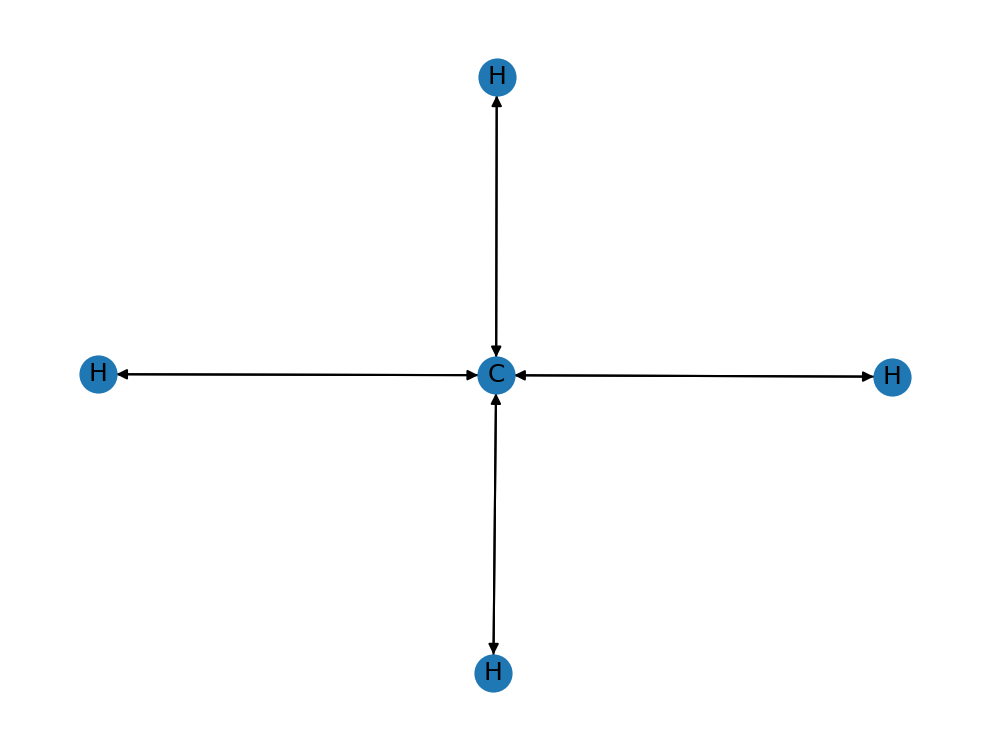

In [9]:
nx.draw(
    G,
    labels=elements
)

In [10]:
# Send data to GPU
data.to(device)
data.is_cuda

True

## Graph convolutions with torch-geometric

In [11]:
import torch_geometric
torch_geometric.nn.GCNConv?

Init signature:
torch_geometric.nn.GCNConv(
    in_channels: int,
    out_channels: int,
    improved: bool = False,
    cached: bool = False,
    add_self_loops: Optional[bool] = None,
    normalize: bool = True,
    bias: bool = True,
    **kwargs,
)
Docstring:     
The graph convolutional operator from the `"Semi-supervised
Classification with Graph Convolutional Networks"
<https://arxiv.org/abs/1609.02907>`_ paper.

.. math::
    \mathbf{X}^{\prime} = \mathbf{\hat{D}}^{-1/2} \mathbf{\hat{A}}
    \mathbf{\hat{D}}^{-1/2} \mathbf{X} \mathbf{\Theta},

where :math:`\mathbf{\hat{A}} = \mathbf{A} + \mathbf{I}` denotes the
adjacency matrix with inserted self-loops and
:math:`\hat{D}_{ii} = \sum_{j=0} \hat{A}_{ij}` its diagonal degree matrix.
The adjacency matrix can include other values than :obj:`1` representing
edge weights via the optional :obj:`edge_weight` tensor.

Its node-wise formulation is given by:

.. math::
    \mathbf{x}^{\prime}_i = \mathbf{\Theta}^{\top} \sum_{j \in
    \mat

In [12]:
import torch.nn as tnn
import torch_geometric.nn as gnn
import torch.nn.functional as F

class BasicGNN(tnn.Module):
    def __init__(self, f_node):
        super().__init__()

        # GCN Layers
        self.conv1 = gnn.GCNConv(f_node, 16)
        self.conv2 = gnn.GCNConv(16, 16)


        # Global sum pooling (in forward)
        # prediction head
        self.out = tnn.Sequential(
            tnn.Linear(16, 64),
            tnn.ReLU(),
            tnn.Linear(64, 1)
        )

    def forward(self, data):
        x = data.x # Shape [N, F_in]
        edge_index = data.edge_index # [2, E], adjacency information
        batch_vector = data.batch # Shape [N,], maps each node to a graph (batch_vector)


        x = F.relu(
            self.conv1(x, edge_index)
        )

        x = F.relu(
            self.conv2(x, edge_index)
        )

        x = gnn.global_add_pool(x, batch_vector)

        x = self.out(x)
        return x

model = BasicGNN(data.x.shape[1]).to(device)
print(model(data))
model

tensor([[-0.1916]], device='cuda:0', grad_fn=<AddmmBackward0>)


BasicGNN(
  (conv1): GCNConv(11, 16)
  (conv2): GCNConv(16, 16)
  (out): Sequential(
    (0): Linear(in_features=16, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=1, bias=True)
  )
)

## Training the model

In [13]:
from torch.utils.data import random_split

train_dataset, val_dataset, test_dataset = random_split(dataset, [0.6, 0.2, 0.2])
print(f'Train dataset has length {len(train_dataset)}')
print(f'Validation dataset has length {len(val_dataset)}')
print(f'Test dataset has length {len(test_dataset)}')

Train dataset has length 78499
Validation dataset has length 26166
Test dataset has length 26166


In [14]:
from torch_geometric.loader import DataLoader

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=4)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=4)

batch = next(iter(train_loader))
batch

DataBatch(x=[568, 11], edge_index=[2, 1182], edge_attr=[1182, 4], y=[32, 19], pos=[568, 3], idx=[32], name=[32], z=[568], batch=[568], ptr=[33])

In [15]:
batch.batch

tensor([ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
         1,  1,  1,  1,  1,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,
         2,  2,  2,  2,  3,  3,  3,  3,  3,  3,  3,  3,  3,  3,  3,  3,  3,  3,
         3,  4,  4,  4,  4,  4,  4,  4,  4,  4,  4,  4,  4,  4,  4,  4,  5,  5,
         5,  5,  5,  5,  5,  5,  5,  5,  5,  5,  5,  5,  6,  6,  6,  6,  6,  6,
         6,  6,  6,  6,  6,  6,  6,  6,  6,  6,  6,  6,  6,  7,  7,  7,  7,  7,
         7,  7,  7,  7,  7,  7,  7,  7,  7,  7,  7,  7,  7,  7,  8,  8,  8,  8,
         8,  8,  8,  8,  8,  8,  8,  8,  8,  8,  8,  8,  8,  8,  8,  8,  8,  8,
         9,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9,
        10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 11, 11, 11,
        11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 12, 12, 12, 12,
        12, 12, 12, 12, 12, 12, 12, 12, 

In [16]:
# Batch offset for each graph
batch.ptr

tensor([  0,  19,  41,  58,  73,  88, 102, 121, 140, 162, 180, 195, 212, 229,
        248, 265, 281, 300, 314, 336, 356, 372, 391, 410, 427, 442, 461, 481,
        500, 515, 530, 553, 568])

In [17]:
# First graph in batch
batch.x[:22]

tensor([[0., 0., 0., 1., 0., 8., 0., 0., 0., 0., 0.],
        [0., 1., 0., 0., 0., 6., 0., 0., 0., 0., 1.],
        [0., 0., 0., 1., 0., 8., 0., 0., 0., 0., 0.],
        [0., 1., 0., 0., 0., 6., 0., 0., 0., 0., 1.],
        [0., 1., 0., 0., 0., 6., 0., 0., 0., 0., 2.],
        [0., 1., 0., 0., 0., 6., 0., 0., 0., 0., 1.],
        [0., 1., 0., 0., 0., 6., 0., 0., 0., 0., 2.],
        [0., 1., 0., 0., 0., 6., 0., 0., 0., 0., 2.],
        [0., 1., 0., 0., 0., 6., 0., 0., 0., 0., 1.],
        [1., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0.,

In [18]:
# Pooling operations
out = torch.zeros([batch.idx.shape[0], batch.x.shape[1]], device=batch.x.device)
out.scatter_reduce_(dim=0, index=batch.batch[:, None].expand_as(batch.x), src=batch.x, reduce='amax')

tensor([[1., 1., 0., 1., 0., 8., 0., 0., 0., 0., 2.],
        [1., 1., 1., 0., 0., 7., 0., 0., 0., 0., 3.],
        [1., 1., 1., 1., 0., 8., 0., 0., 0., 0., 2.],
        [1., 1., 0., 1., 0., 8., 0., 0., 0., 0., 2.],
        [1., 1., 1., 1., 0., 8., 0., 0., 0., 0., 2.],
        [1., 1., 1., 1., 0., 8., 0., 0., 0., 0., 2.],
        [1., 1., 0., 1., 0., 8., 0., 0., 0., 0., 2.],
        [1., 1., 0., 1., 0., 8., 0., 0., 0., 0., 2.],
        [1., 1., 1., 1., 0., 8., 0., 0., 0., 0., 3.],
        [1., 1., 1., 1., 0., 8., 0., 0., 0., 0., 2.],
        [1., 1., 0., 1., 0., 8., 0., 0., 0., 0., 2.],
        [1., 1., 0., 1., 0., 8., 0., 0., 0., 0., 2.],
        [1., 1., 1., 1., 0., 8., 0., 0., 0., 0., 3.],
        [1., 1., 0., 1., 0., 8., 0., 0., 0., 0., 3.],
        [1., 1., 1., 1., 0., 8., 0., 0., 0., 0., 2.],
        [1., 1., 1., 0., 0., 7., 0., 0., 0., 0., 2.],
        [1., 1., 0., 1., 0., 8., 0., 0., 0., 0., 2.],
        [1., 1., 1., 1., 0., 8., 0., 0., 0., 0., 2.],
        [1., 1., 1., 0., 0.,

In [19]:
model(batch.to(device))

tensor([[-1.3154],
        [-1.3308],
        [-1.2473],
        [-1.2745],
        [-1.2217],
        [-1.1766],
        [-1.3357],
        [-1.2985],
        [-1.3176],
        [-1.2701],
        [-1.2569],
        [-1.3008],
        [-1.2306],
        [-1.2800],
        [-1.2230],
        [-1.2043],
        [-1.3341],
        [-1.2234],
        [-1.3340],
        [-1.1994],
        [-1.2264],
        [-1.2867],
        [-1.2611],
        [-1.2146],
        [-1.2111],
        [-1.3365],
        [-1.2984],
        [-1.3040],
        [-1.2656],
        [-1.2086],
        [-1.3650],
        [-1.2098]], device='cuda:0', grad_fn=<AddmmBackward0>)

In [20]:
from tqdm.notebook import tqdm

def train(model, optimizer, train_loader, val_loader, num_epochs=10, target_idx=1):
    train_loss = []
    val_loss = []
    
    for epoch in range(num_epochs):
    
        loss_ = 0
        graphs_ = 0
        model.train()
        for batch in tqdm(train_loader, leave=False):
            # Send data to device
            batch.to(device)
    
            # Make a prediction, compute the loss
            y_pred = model(batch)
            loss = F.mse_loss(y_pred, batch.y[:, target_idx, None])
    
            # Backprop, apply gradients, reset optimizer
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
    
            # Logging
            loss_ += loss.item()
            graphs_ += batch.num_graphs
    
        train_loss.append(loss_ / graphs_)
        
        loss_ = 0
        graphs_ = 0
        model.eval()
        with torch.no_grad():
            for batch in tqdm(val_loader, leave=False):
                # Send data to device
                batch.to(device)
        
                # Make a prediction, compute the loss
                y_pred = model(batch)
                loss = F.mse_loss(y_pred, batch.y[:, target_idx, None])
        
                # Logging
                loss_ += loss.item()
                graphs_ += batch.num_graphs
    
        val_loss.append(loss_ / graphs_)
        print(f"Epoch: {epoch} | "
              f"train loss: {train_loss[-1]:.3f} | "
              f"val loss: {val_loss[-1]:.3f}")

    return train_loss, val_loss

model = BasicGNN(data.x.shape[1])
model = model.to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)

train_loss, val_loss = train(model, optimizer, train_loader, val_loader, num_epochs=5)

  0%|          | 0/2454 [00:00<?, ?it/s]

  0%|          | 0/818 [00:00<?, ?it/s]

Epoch: 0 | train loss: 0.975 | val loss: 0.198


  0%|          | 0/2454 [00:00<?, ?it/s]

  0%|          | 0/818 [00:00<?, ?it/s]

...

  0%|          | 0/818 [00:00<?, ?it/s]

Epoch: 3 | train loss: 0.187 | val loss: 0.199


  0%|          | 0/2454 [00:00<?, ?it/s]

  0%|          | 0/818 [00:00<?, ?it/s]

Epoch: 4 | train loss: 0.170 | val loss: 0.149


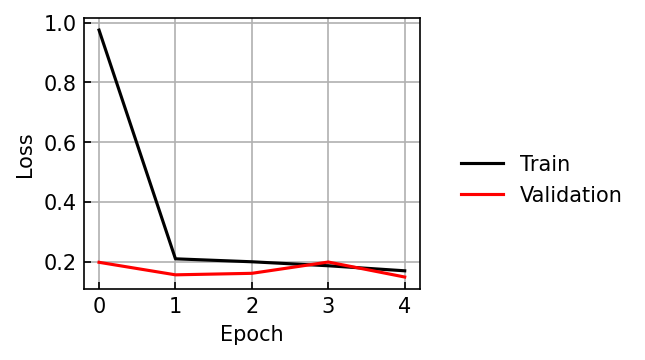

In [21]:
fig, ax = plt.subplots(1, 1, sharex=True, figsize=(3, 2.5))

ax.plot(train_loss, color='black', label='Train')
ax.plot(val_loss, color='red', label='Validation')
ax.set(xlabel='Epoch', ylabel='Loss')

fig.legend(*ax.get_legend_handles_labels(), 
           loc='center left', bbox_to_anchor=[1, 0.5], framealpha=0)

plt.tight_layout()

In [22]:
y_true, y_pred = [], []
model.eval()
target_idx = 1

test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2)
with torch.no_grad():
    for batch in tqdm(test_loader):
        yp = model(batch.to(device))
        
        y_true.append(batch.y[:, target_idx].cpu().numpy())
        y_pred.append(yp.squeeze().cpu().numpy())

y_true = np.concatenate(y_true)
y_pred = np.concatenate(y_pred)
print(y_true.shape, y_pred.shape)

  0%|          | 0/818 [00:00<?, ?it/s]

(26166,) (26166,)


Mean absolute difference: 1.6 a_0^3


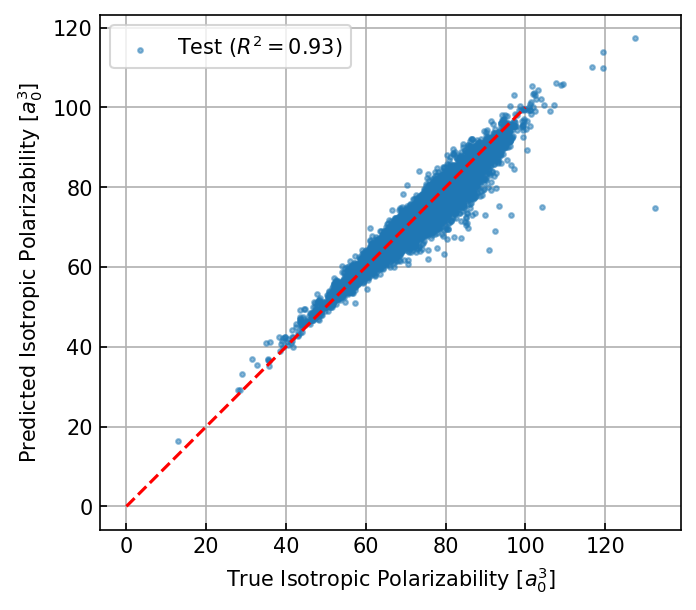

In [23]:
from sklearn.metrics import r2_score
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
ax.scatter(y_true, y_pred, s=5, alpha=0.5, label=f'Test ($R^2 = {r2_score(y_true, y_pred):.2f}$)')
ax.plot([0,100], [0, 100], color='red', linestyle='--')
ax.set(
    xlabel='True Isotropic Polarizability [$a_0^3$]',
    ylabel='Predicted Isotropic Polarizability [$a_0^3$]',
    aspect='equal',
)
ax.legend();

print(f'Mean absolute difference: {np.mean(np.abs(y_true - y_pred)):.1f} a_0^3')

## Scaled Dot Product Attention

Attention allows the model to determine *importance weights* for each incoming message. That is, 
\begin{align*}
    \mathbf{x}^{(t+1)}_i = \mathbf{W}_1 \mathbf{x}^{(t)}_i + \sum_{j \in \mathcal{N}(i)} \alpha_{ij} \ \mathbf{W}_V \mathbf{x}_j^{(t)}
\end{align*}

Here $W_1$ is the self-update matrix, $W_V$ is a matrix that maps neighbor node features into an incoming message *value*, and $alpha_{ij}$ is an **attention weight** set by the alignment between a node's *query* and a neighbor's *key*.  


\begin{align*}
    \alpha_{ij} = \text{softmax} \left( 
        \frac{
            \left( \mathbf{W}_Q \mathbf{x}_i \right)^{\top} \left( \mathbf{W}_K \mathbf{x}_j \right) 
        }{\sqrt{d}}
    \right)
\end{align*}

In [24]:
import torch_geometric
torch_geometric.nn.TransformerConv?

Init signature:
torch_geometric.nn.TransformerConv(
    in_channels: Union[int, Tuple[int, int]],
    out_channels: int,
    heads: int = 1,
    concat: bool = True,
    beta: bool = False,
    dropout: float = 0.0,
    edge_dim: Optional[int] = None,
    bias: bool = True,
    root_weight: bool = True,
    **kwargs,
)
Docstring:     
The graph transformer operator from the `"Masked Label Prediction:
Unified Message Passing Model for Semi-Supervised Classification"
<https://arxiv.org/abs/2009.03509>`_ paper.

.. math::
    \mathbf{x}^{\prime}_i = \mathbf{W}_1 \mathbf{x}_i +
    \sum_{j \in \mathcal{N}(i)} \alpha_{i,j} \mathbf{W}_2 \mathbf{x}_{j},

where the attention coefficients :math:`\alpha_{i,j}` are computed via
multi-head dot product attention:

.. math::
    \alpha_{i,j} = \textrm{softmax} \left(
    \frac{(\mathbf{W}_3\mathbf{x}_i)^{\top} (\mathbf{W}_4\mathbf{x}_j)}
    {\sqrt{d}} \right)

Args:
    in_channels (int or tuple): Size of each input sample, or :obj:`-1` to
        

In [25]:
import torch.nn as tnn
import torch_geometric.nn as gnn
import torch.nn.functional as F

class ScaledDotProductAttentionGNN(tnn.Module):
    def __init__(self, f_node, f_edge):
        super().__init__()

        self.conv1 = gnn.TransformerConv(f_node, 16, heads=1)
        self.conv2 = gnn.TransformerConv(16, 16, heads=1)

        # Global sum pooling (in forward)
        # prediction head
        self.out = tnn.Sequential(
            tnn.Linear(16, 64),
            tnn.ReLU(),
            tnn.Linear(64, 1)
        )

    def forward(self, data):
        x = data.x # Shape [N, F_in]
        edge_index = data.edge_index # [2, E]
        batch_vector = data.batch # Shape [N,], maps each node to a graph

        x = F.relu(
            self.conv1(x, edge_index)
        )

        x = F.relu(
            self.conv2(x, edge_index)
        )

        x = gnn.global_add_pool(x, batch_vector)

        x = self.out(x)
        return x

model = ScaledDotProductAttentionGNN(data.x.shape[1], data.edge_attr.shape[1]).to(device)
print(model(data))
model

tensor([[1.2002]], device='cuda:0', grad_fn=<AddmmBackward0>)


ScaledDotProductAttentionGNN(
  (conv1): TransformerConv(11, 16, heads=1)
  (conv2): TransformerConv(16, 16, heads=1)
  (out): Sequential(
    (0): Linear(in_features=16, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=1, bias=True)
  )
)

In [26]:
model = ScaledDotProductAttentionGNN(data.x.shape[1], data.edge_attr.shape[1])
model = model.to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)

train_loss, val_loss = train(model, optimizer, train_loader, val_loader, num_epochs=5)

  0%|          | 0/2454 [00:00<?, ?it/s]

  0%|          | 0/818 [00:00<?, ?it/s]

Epoch: 0 | train loss: 0.655 | val loss: 0.185


  0%|          | 0/2454 [00:00<?, ?it/s]

  0%|          | 0/818 [00:00<?, ?it/s]

...

  0%|          | 0/818 [00:00<?, ?it/s]

Epoch: 3 | train loss: 0.164 | val loss: 0.193


  0%|          | 0/2454 [00:00<?, ?it/s]

  0%|          | 0/818 [00:00<?, ?it/s]

Epoch: 4 | train loss: 0.146 | val loss: 0.099


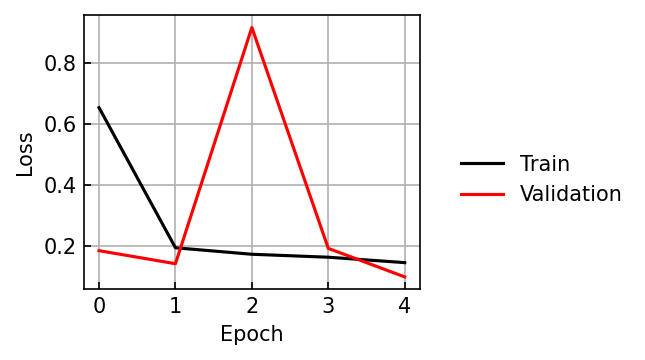

In [27]:
fig, ax = plt.subplots(1, 1, sharex=True, figsize=(3, 2.5))

ax.plot(train_loss, color='black', label='Train')
ax.plot(val_loss, color='red', label='Validation')
ax.set(xlabel='Epoch', ylabel='Loss')

fig.legend(*ax.get_legend_handles_labels(), 
           loc='center left', bbox_to_anchor=[1, 0.5], framealpha=0)

plt.tight_layout()

In [28]:
y_true, y_pred = [], []
model.eval()
target_idx = 1

test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2)
with torch.no_grad():
    for batch in tqdm(test_loader):
        yp = model(batch.to(device))
        
        y_true.append(batch.y[:, target_idx].cpu().numpy())
        y_pred.append(yp.squeeze().cpu().numpy())

y_true = np.concatenate(y_true)
y_pred = np.concatenate(y_pred)
print(y_true.shape, y_pred.shape)

  0%|          | 0/818 [00:00<?, ?it/s]

(26166,) (26166,)


Mean absolute difference: 1.3 a_0^3


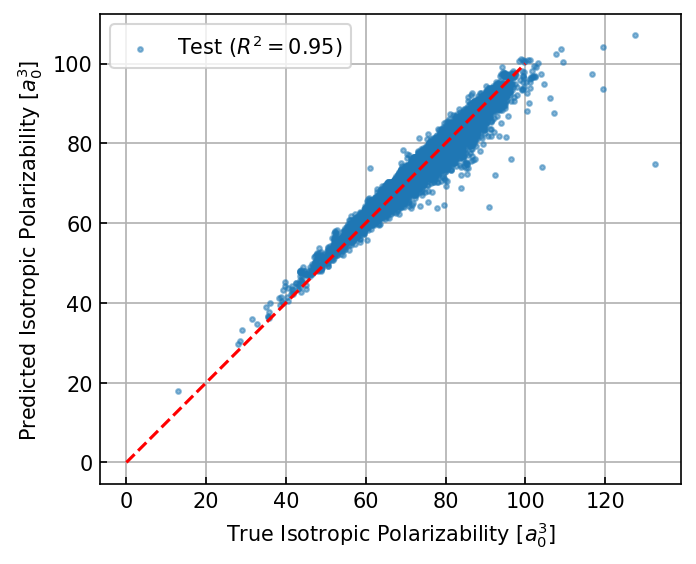

In [29]:
from sklearn.metrics import r2_score
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
ax.scatter(y_true, y_pred, s=5, alpha=0.5, label=f'Test ($R^2 = {r2_score(y_true, y_pred):.2f}$)')
ax.plot([0,100], [0, 100], color='red', linestyle='--')
ax.set(
    xlabel='True Isotropic Polarizability [$a_0^3$]',
    ylabel='Predicted Isotropic Polarizability [$a_0^3$]',
    aspect='equal',
)
ax.legend();

print(f'Mean absolute difference: {np.mean(np.abs(y_true - y_pred)):.1f} a_0^3')

## Graph Attention Networks

As another attention mechanism, let's consider the Graph Attention Network formulation ([link](https://arxiv.org/abs/1710.10903)). Here, the updated value at each node is a weighted aggregation
\begin{align*}
    \mathbf{x}^{(t+1)}_i = \sum_{j \in \mathcal{N}(i) \cup \{i\}} \alpha_{ij} \mathbf{W} \mathbf{x}_j
\end{align*}

The weights are computed using a normalized *attention* mechanism

\begin{align*}
    \alpha_{ij} = \frac{
        \exp \left( \text{LeakyReLU} \left( 
            \mathbf{a}_s \mathbf{W} \mathbf{x}^{(t)}_i + 
            \mathbf{a}_t \mathbf{W} \mathbf{x}^{(t)}_j + 
            \mathbf{a}_e \mathbf{W}_e \mathbf{e}_{ij} \right) \right) 
    }{
        \sum_{k \in \mathcal{N}(i) \cup \{i\}} \exp \left( \text{LeakyReLU} \left( 
            \mathbf{a}_s \mathbf{W} \mathbf{x}^{(t)}_i + 
            \mathbf{a}_t \mathbf{W} \mathbf{x}^{(t)}_k + 
            \mathbf{a}_e \mathbf{W}_e \mathbf{e}_{ik} \right) \right) 
    }
\end{align*}

Here, $\mathbf{W}$ is a learnable linear transformation that is applied to all node values. $\mathbf{a}_s, \mathbf{a}_t$ are weight vectors applied to the transformed feature values. There is an additional transformation matrix and weight for edge features in our case. The denominator is a normalization factor meant to ensure that all incoming weights to a particular node sum to 1.

This looks like a complete mess, right? Well really, what this is doing is applying a single-layer MLP to the concatenated node and neighbor features. 
\begin{align*}
    \tilde{\alpha}_{ij} &= \text{LeakyRELU} \left( \left[ \mathbf{a}_s, \mathbf{a}_n \right] \cdot \left[ \mathbf{W}\, \mathbf{x}_i^{(t)}, \mathbf{W} \,\mathbf{x}_{j}^{(t)} \right] \right) \\
    &= \text{LeakyRELU} \left( \mathbf{a} \cdot \mathbf{h} \right) \\
    \alpha_{ij} &= \text{softmax}_j ( \tilde{\alpha}_{ij})
\end{align*}

In [30]:
import torch_geometric
torch_geometric.nn.GATConv?

Init signature:
torch_geometric.nn.GATConv(
    in_channels: Union[int, Tuple[int, int]],
    out_channels: int,
    heads: int = 1,
    concat: bool = True,
    negative_slope: float = 0.2,
    dropout: float = 0.0,
    add_self_loops: bool = True,
    edge_dim: Optional[int] = None,
    fill_value: Union[float, torch.Tensor, str] = 'mean',
    bias: bool = True,
    residual: bool = False,
    **kwargs,
)
Docstring:     
The graph attentional operator from the `"Graph Attention Networks"
<https://arxiv.org/abs/1710.10903>`_ paper.

.. math::
    \mathbf{x}^{\prime}_i = \sum_{j \in \mathcal{N}(i) \cup \{ i \}}
    \alpha_{i,j}\mathbf{\Theta}_t\mathbf{x}_{j},

where the attention coefficients :math:`\alpha_{i,j}` are computed as

.. math::
    \alpha_{i,j} =
    \frac{
    \exp\left(\mathrm{LeakyReLU}\left(
    \mathbf{a}^{\top}_{s} \mathbf{\Theta}_{s}\mathbf{x}_i
    + \mathbf{a}^{\top}_{t} \mathbf{\Theta}_{t}\mathbf{x}_j
    \right)\right)}
    {\sum_{k \in \mathcal{N}(i) \cup \{ i \

In [31]:
import torch.nn as tnn
import torch_geometric.nn as gnn
import torch.nn.functional as F

class AttentionGNN(tnn.Module):
    def __init__(self, f_node, f_edge):
        super().__init__()

        self.conv1 = gnn.GATConv(f_node, 16, heads=1)
        self.conv2 = gnn.GATConv(16, 16, heads=1)

        # Global sum pooling (in forward)
        # prediction head
        self.out = tnn.Sequential(
            tnn.Linear(16, 64),
            tnn.ReLU(),
            tnn.Linear(64, 1)
        )

    def forward(self, data):
        x = data.x # Shape [N, F_in]
        edge_index = data.edge_index # [2, E]
        batch_vector = data.batch # Shape [N,], maps each node to a graph

        x = F.relu(
            self.conv1(x, edge_index)
        )

        x = F.relu(
            self.conv2(x, edge_index)
        )

        x = gnn.global_add_pool(x, batch_vector)

        x = self.out(x)
        return x

model = AttentionGNN(data.x.shape[1], data.edge_attr.shape[1]).to(device)
print(model(data))
model

tensor([[-0.7839]], device='cuda:0', grad_fn=<AddmmBackward0>)


AttentionGNN(
  (conv1): GATConv(11, 16, heads=1)
  (conv2): GATConv(16, 16, heads=1)
  (out): Sequential(
    (0): Linear(in_features=16, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=1, bias=True)
  )
)

In [32]:
model = AttentionGNN(data.x.shape[1], data.edge_attr.shape[1])
model = model.to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)

train_loss, val_loss = train(model, optimizer, train_loader, val_loader, num_epochs=5)

  0%|          | 0/2454 [00:00<?, ?it/s]

  0%|          | 0/818 [00:00<?, ?it/s]

Epoch: 0 | train loss: 0.704 | val loss: 0.185


  0%|          | 0/2454 [00:00<?, ?it/s]

  0%|          | 0/818 [00:00<?, ?it/s]

...

  0%|          | 0/818 [00:00<?, ?it/s]

Epoch: 3 | train loss: 0.170 | val loss: 0.161


  0%|          | 0/2454 [00:00<?, ?it/s]

  0%|          | 0/818 [00:00<?, ?it/s]

Epoch: 4 | train loss: 0.157 | val loss: 0.143


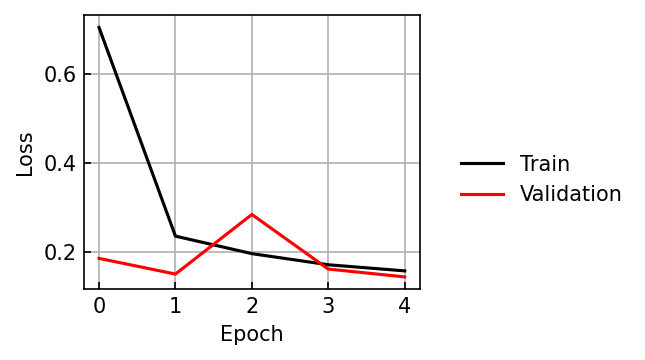

In [33]:
fig, ax = plt.subplots(1, 1, sharex=True, figsize=(3, 2.5))

ax.plot(train_loss, color='black', label='Train')
ax.plot(val_loss, color='red', label='Validation')
ax.set(xlabel='Epoch', ylabel='Loss')

fig.legend(*ax.get_legend_handles_labels(), 
           loc='center left', bbox_to_anchor=[1, 0.5], framealpha=0)

plt.tight_layout()

In [34]:
y_true, y_pred = [], []
model.eval()

test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2)
with torch.no_grad():
    for batch in tqdm(test_loader):
        yp = model(batch.to(device))
        
        y_true.append(batch.y[:, target_idx].cpu().numpy())
        y_pred.append(yp.squeeze().cpu().numpy())

y_true = np.concatenate(y_true)
y_pred = np.concatenate(y_pred)
print(y_true.shape, y_pred.shape)

  0%|          | 0/818 [00:00<?, ?it/s]

(26166,) (26166,)


Mean absolute difference: 1.7 a_0^3


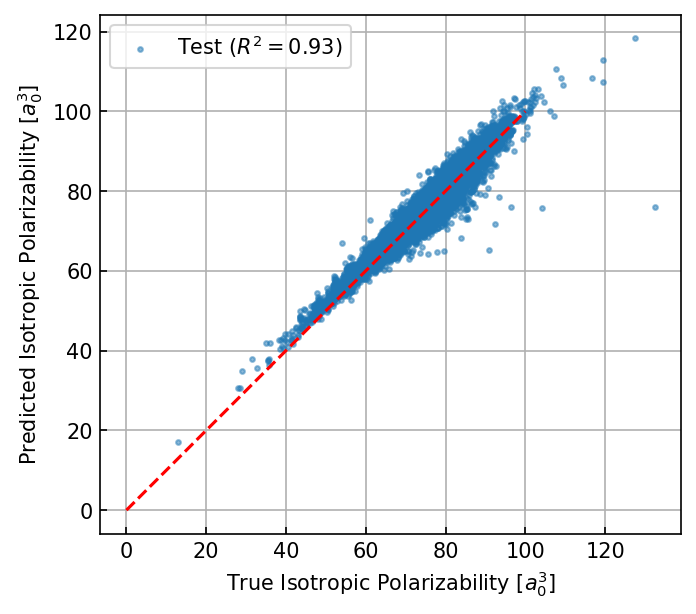

In [35]:
from sklearn.metrics import r2_score
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
ax.scatter(y_true, y_pred, s=5, alpha=0.5, label=f'Test ($R^2 = {r2_score(y_true, y_pred):.2f}$)')
ax.plot([0,100], [0, 100], color='red', linestyle='--')
ax.set(
    xlabel='True Isotropic Polarizability [$a_0^3$]',
    ylabel='Predicted Isotropic Polarizability [$a_0^3$]',
    aspect='equal',
)
ax.legend();

print(f'Mean absolute difference: {np.mean(np.abs(y_true - y_pred)):.1f} a_0^3')

## Edge-aware convolutions with torch-geometric

Our edges contain important features too! For example, they could indicate whether there is an ionic or covalent bond, etc. So our message passing needs to accommodate these edge features. 

`NNConv` is a layer that learns an **edge-conditioned convolution** 
\begin{align*}
    \mathbf{x}^{(t+1)}_i = \mathbf{x}^{(t)}_i \mathbf{W} + \sum_{j \in \mathcal{N}(i)} \mathbf{x}^{(t)}_j h_{\theta}(\mathbf{e}_{ij})
\end{align*}
where $h_{\theta}$ can be a neural network such as an MLP to represent an arbitrary functional relationship between the edge features and the corresponding importance weight.

Is this a permutation invariant operation?

In [36]:
import torch_geometric
torch_geometric.nn.NNConv?

Init signature:
torch_geometric.nn.NNConv(
    in_channels: Union[int, Tuple[int, int]],
    out_channels: int,
    nn: Callable,
    aggr: str = 'add',
    root_weight: bool = True,
    bias: bool = True,
    **kwargs,
)
Docstring:     
The continuous kernel-based convolutional operator from the
`"Neural Message Passing for Quantum Chemistry"
<https://arxiv.org/abs/1704.01212>`_ paper.

This convolution is also known as the edge-conditioned convolution from the
`"Dynamic Edge-Conditioned Filters in Convolutional Neural Networks on
Graphs" <https://arxiv.org/abs/1704.02901>`_ paper (see
:class:`torch_geometric.nn.conv.ECConv` for an alias):

.. math::
    \mathbf{x}^{\prime}_i = \mathbf{\Theta} \mathbf{x}_i +
    \sum_{j \in \mathcal{N}(i)} \mathbf{x}_j \cdot
    h_{\mathbf{\Theta}}(\mathbf{e}_{i,j}),

where :math:`h_{\mathbf{\Theta}}` denotes a neural network, *.i.e.*
a MLP.

Args:
    in_channels (int or tuple): Size of each input sample, or :obj:`-1` to
        derive the size from 

In [37]:
import torch.nn as tnn
import torch_geometric.nn as gnn
import torch.nn.functional as F

class EdgeAwareGNN(tnn.Module):
    def __init__(self, f_node, f_edge):
        super().__init__()

        # nn for conv1
        conv1_nn = tnn.Sequential(
            tnn.Linear(f_edge, 32),
            tnn.ReLU(),
            tnn.Linear(32, f_node * 16) # Outputs a [f_node, 16] transformation matrix
        )
        # conv1
        self.conv1 = gnn.NNConv(f_node, 16, conv1_nn)

        # nn for conv2
        conv2_nn = tnn.Sequential(
            tnn.Linear(f_edge, 32),
            tnn.ReLU(),
            tnn.Linear(32, 16 * 16) # Outputs a [16, 16] transformation matrix
        )
        # conv2
        self.conv2 = gnn.NNConv(16, 16, conv2_nn)

        # Global sum pooling (in forward)
        # prediction head
        self.out = tnn.Sequential(
            tnn.Linear(16, 64),
            tnn.ReLU(),
            tnn.Linear(64, 1)
        )

    def forward(self, data):
        x = data.x # Shape [N, F_in]
        edge_index = data.edge_index # [2, E]
        batch_vector = data.batch # Shape [N,], maps each node to a graph
        edge_attr = data.edge_attr # [E, F_edge]

        x = F.relu(
            self.conv1(x, edge_index, edge_attr)
        )

        x = F.relu(
            self.conv2(x, edge_index, edge_attr)
        )

        x = gnn.global_add_pool(x, batch_vector)

        x = self.out(x)
        return x

model = EdgeAwareGNN(data.x.shape[1], data.edge_attr.shape[1]).to(device)
print(model(data))
model

tensor([[-0.1099]], device='cuda:0', grad_fn=<AddmmBackward0>)


EdgeAwareGNN(
  (conv1): NNConv(11, 16, aggr=add, nn=Sequential(
    (0): Linear(in_features=4, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=176, bias=True)
  ))
  (conv2): NNConv(16, 16, aggr=add, nn=Sequential(
    (0): Linear(in_features=4, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=256, bias=True)
  ))
  (out): Sequential(
    (0): Linear(in_features=16, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=1, bias=True)
  )
)

In [38]:
model = EdgeAwareGNN(data.x.shape[1], data.edge_attr.shape[1])
model = model.to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)

train_loss, val_loss = train(model, optimizer, train_loader, val_loader, num_epochs=5)

  0%|          | 0/2454 [00:00<?, ?it/s]

  0%|          | 0/818 [00:00<?, ?it/s]

Epoch: 0 | train loss: 1.087 | val loss: 0.198


  0%|          | 0/2454 [00:00<?, ?it/s]

  0%|          | 0/818 [00:00<?, ?it/s]

...

  0%|          | 0/818 [00:00<?, ?it/s]

Epoch: 3 | train loss: 0.125 | val loss: 0.072


  0%|          | 0/2454 [00:00<?, ?it/s]

  0%|          | 0/818 [00:00<?, ?it/s]

Epoch: 4 | train loss: 0.117 | val loss: 0.216


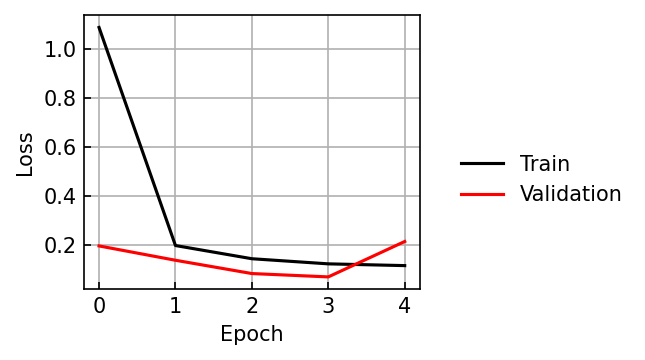

In [39]:
fig, ax = plt.subplots(1, 1, sharex=True, figsize=(3, 2.5))

ax.plot(train_loss, color='black', label='Train')
ax.plot(val_loss, color='red', label='Validation')
ax.set(xlabel='Epoch', ylabel='Loss')

fig.legend(*ax.get_legend_handles_labels(), 
           loc='center left', bbox_to_anchor=[1, 0.5], framealpha=0)

plt.tight_layout()

In [40]:
y_true, y_pred = [], []
model.eval()

test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2)
with torch.no_grad():
    for batch in tqdm(test_loader):
        yp = model(batch.to(device))
        
        y_true.append(batch.y[:, target_idx].cpu().numpy())
        y_pred.append(yp.squeeze().cpu().numpy())

y_true = np.concatenate(y_true)
y_pred = np.concatenate(y_pred)
print(y_true.shape, y_pred.shape)

  0%|          | 0/818 [00:00<?, ?it/s]

(26166,) (26166,)


Mean absolute difference: 2.3 a_0^3


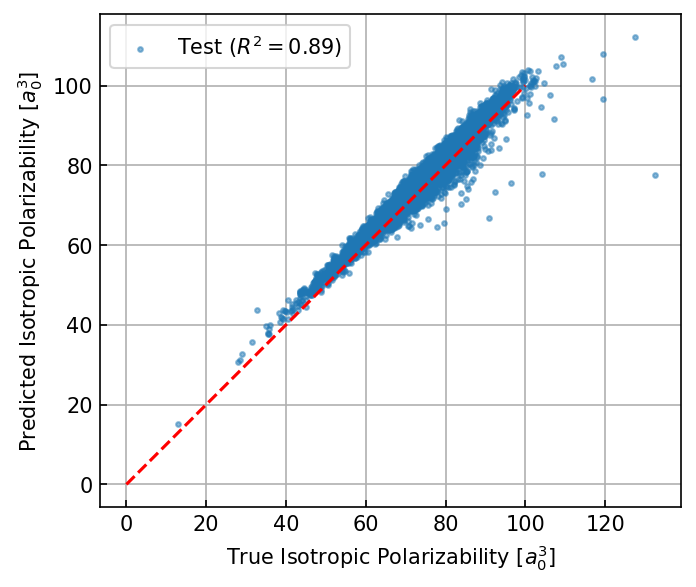

In [41]:
from sklearn.metrics import r2_score
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
ax.scatter(y_true, y_pred, s=5, alpha=0.5, label=f'Test ($R^2 = {r2_score(y_true, y_pred):.2f}$)')
ax.plot([0,100], [0, 100], color='red', linestyle='--')
ax.set(
    xlabel='True Isotropic Polarizability [$a_0^3$]',
    ylabel='Predicted Isotropic Polarizability [$a_0^3$]',
    aspect='equal',
)
ax.legend();

print(f'Mean absolute difference: {np.mean(np.abs(y_true - y_pred)):.1f} a_0^3')

## A veritable zoo of graph operations

You can get a big list of GNN operations [here](https://pytorch-geometric.readthedocs.io/en/2.6.1/modules/nn.html#convolutional-layers). Pick one and implement it. What score do you get?